# Multimodal RAG: ViDoRe V3 Industrial (Page Level)

Loads the `vidore/vidore_v3_industrial` dataset from Hugging Face.

Each config has a single `test` split:

| config | contents |
|---|---|
| `corpus` | one row per page: `corpus_id`, `image`, `doc_id`, `markdown`, `page_number_in_doc` |
| `queries` | `query_id`, `query`, `answer`, `query_types`, ... |
| `qrels` | relevance labels linking `query_id` to `corpus_id` (with `score`, `bounding_boxes`), used as the retrieval ground truth |

In [3]:
!pip install -q datasets pillow pandas

## Load and Inspect dataset

In [4]:
from datasets import load_dataset

ds_corpus = load_dataset("vidore/vidore_v3_industrial", "corpus")
ds_labels = load_dataset("vidore/vidore_v3_industrial", "qrels")
ds_queries = load_dataset("vidore/vidore_v3_industrial", "queries")

In [5]:
for name, ds in [("corpus", ds_corpus), ("queries", ds_queries), ("qrels", ds_labels)]:
    print(f"{name}: {len(ds['test'])} rows, columns {list(ds['test'].features)}")

corpus: 5244 rows, columns ['corpus_id', 'image', 'doc_id', 'markdown', 'page_number_in_doc']
queries: 1698 rows, columns ['query_id', 'query', 'language', 'query_types', 'query_format', 'content_type', 'raw_answers', 'query_generator', 'query_generation_pipeline', 'source_type', 'query_type_for_generation', 'answer']
qrels: 9684 rows, columns ['query_id', 'corpus_id', 'score', 'content_type', 'bounding_boxes']


AFD-091005-056 page 0
TO 00-25-172CL-2
TECHNICAL MANUAL
CHECKLIST
CONCURRENT SERVICING OF COMMERCIAL CONTRACT CARGO AIRCRA


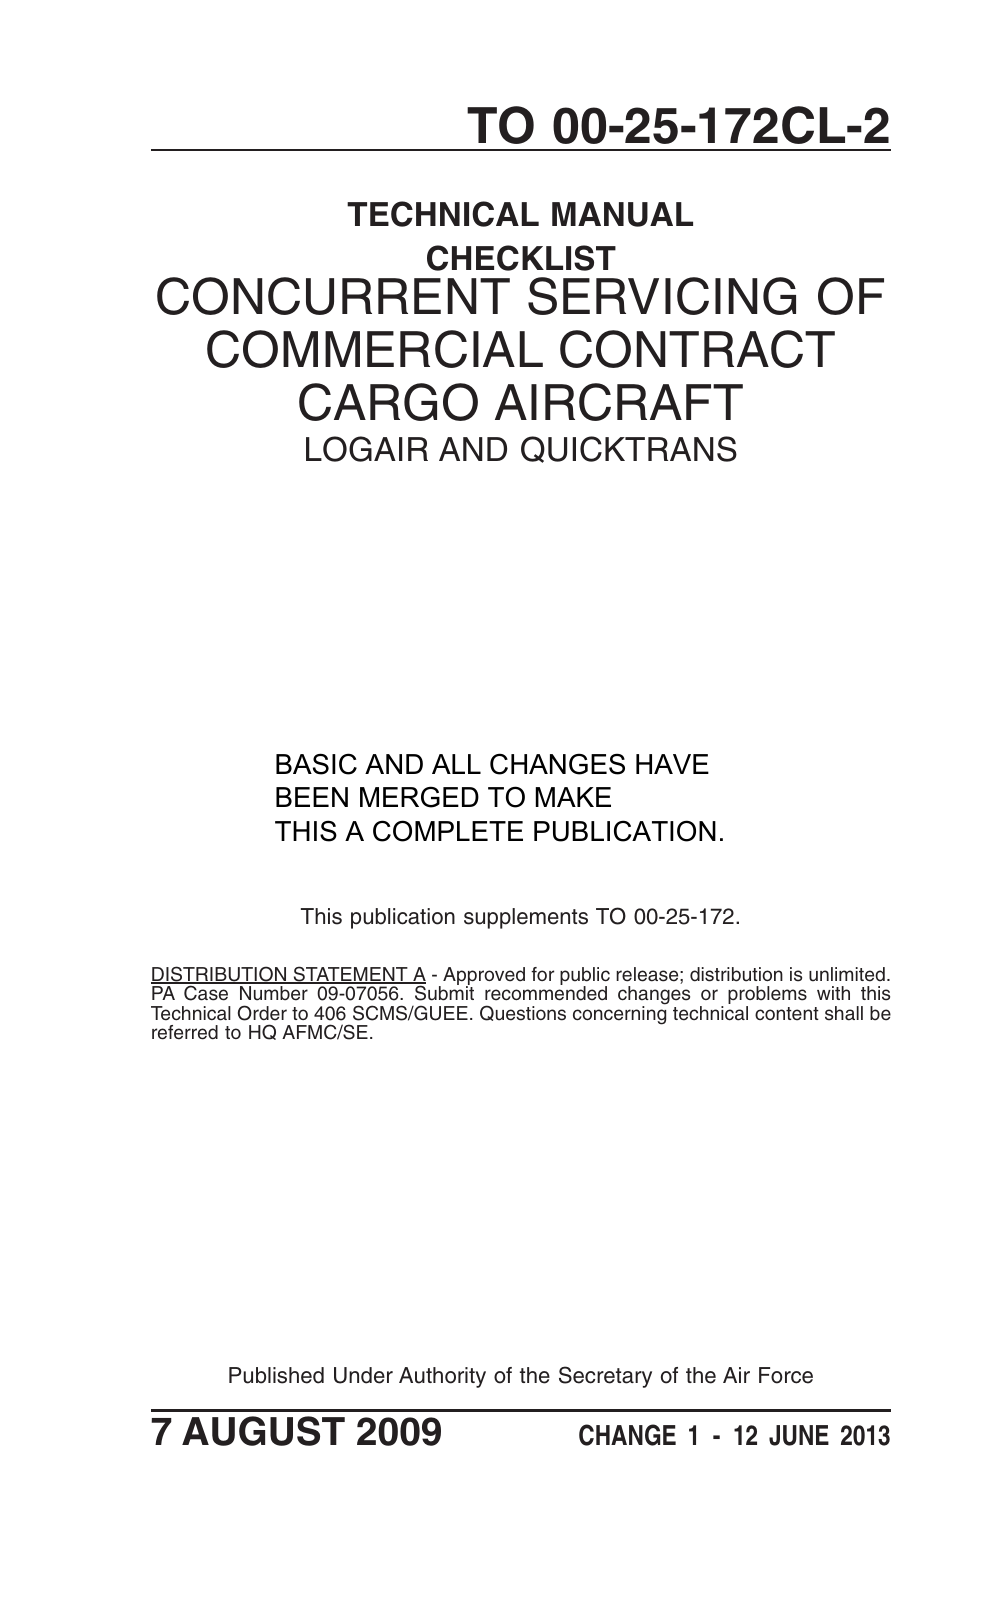

In [ ]:
# A sample corpus page: image + OCR/markdown text
from IPython.display import display

page = ds_corpus["test"][0]
print(page["doc_id"], "page", page["page_number_in_doc"])
print(page["markdown"][:100])
display(page["image"])

In [ ]:
# A sample query with its relevant pages
q = ds_queries["test"][0]
relevant = [r["corpus_id"] for r in ds_labels["test"] if r["query_id"] == q["query_id"]]

print("query:", q["query"])
print("answer:", q["answer"])
print("relevant corpus_ids:", relevant)

query: Which components are involved in the emergency shutdown procedure and what are their roles in ensuring system isolation?
answer: The components involved in the emergency shutdown procedure are the Pneumatic System and the N2 Bottle Cylinder, which power the emergency shutdown system. The Radio Remote Control System Keypad is used to activate the emergency shutdown and stop fuel flow. The E-Stop Switch is used to initiate an emergency shutdown. The Globe valve controls the propane flow, and the Pilot valve controls the COAX valve. The Control stand contains the valves.
relevant corpus_ids: [53, 163, 166, 175, 208, 214, 220, 222, 225, 226]


In [6]:
from collections import defaultdict


def build_qrels(qrels) -> dict[int, set[int]]:
    out = defaultdict(set)
    for row in qrels:
        if row["score"] > 0:
            out[row["query_id"]].add(row["corpus_id"])
    return dict(out)


qrels_by_query = build_qrels(ds_labels["test"])  # query_id -> relevant corpus_ids (retrieval ground truth)

print(f"{len(qrels_by_query)} queries with relevance labels")

1698 queries with relevance labels


## Retrieval setup

Each page's `markdown` is indexed as one document, so the retrieval unit is the same as the unit in the page-level `qrels`. `to_pages` turns a score per page into a ranked list of `corpus_id`s.

In [7]:
!pip install -q bm25s PyStemmer "sentence-transformers" "transformers"

In [8]:
import numpy as np

# Read columns directly: iterating rows would decode every page image just to get the id and text.
page_ids = ds_corpus["test"]["corpus_id"]
page_texts = [text or "" for text in ds_corpus["test"]["markdown"]]
print(f"{len(page_texts)} pages, longest {max(map(len, page_texts))} characters")


def to_pages(page_scores: np.ndarray, k: int) -> list[int]:
    """Ranked list of the top-k page corpus_ids for one score per page."""
    return [page_ids[i] for i in np.argsort(-page_scores)[:k]]

5244 pages, longest 6852 characters


## Sparse retrieval (keyword, BM25s)

Scores pages by weighted keyword overlap with the query using [`bm25s`](https://github.com/xhluca/bm25s). Text is lowercased, English stopwords are dropped and words are stemmed, so "servicing" and "service" match. It is strong on exact terms such as part numbers and manual codes, and blind to synonyms.

In [9]:
import bm25s
import Stemmer

stemmer = Stemmer.Stemmer("english")

bm25 = bm25s.BM25()
bm25.index(bm25s.tokenize(page_texts, stopwords="en", stemmer=stemmer))

def sparse_pages(query: str, k: int) -> list[int]:
    # return_ids=False gives plain string tokens, which get_scores maps through the index vocabulary
    q_tokens = bm25s.tokenize(query, stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]
    return to_pages(bm25.get_scores(q_tokens), k)

Split strings:   0%|          | 0/5244 [00:00<?, ?it/s]

Stem Tokens:   0%|          | 0/5244 [00:00<?, ?it/s]

DEBUG:bm25s:Building index from IDs objects


BM25S Count Tokens:   0%|          | 0/5244 [00:00<?, ?it/s]

BM25S Compute Scores:   0%|          | 0/5244 [00:00<?, ?it/s]

## Dense retrieval (semantic)

Embeds every page with `Qwen/Qwen3-Embedding-0.6B` (1024-dim, 32k context, instruction-aware) and ranks by cosine similarity to the query embedding. Queries are prefixed with a task instruction, documents are not. It matches meaning rather than exact words.

In [10]:
import torch
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
# Qwen3-Embedding is instruction-aware: queries get a task prompt, documents are embedded as-is.
QUERY_PROMPT = "Instruct: Given a question about a technical manual, retrieve the page that answers it\nQuery:"

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(EMBED_MODEL, device=device, tokenizer_kwargs={"padding_side": "left"})
embedder.max_seq_length = 2048  # whole pages; longer pages are truncated
if device == "cuda":
    embedder.half()

page_emb = embedder.encode(page_texts, batch_size=4, normalize_embeddings=True, show_progress_bar=True)


def dense_pages(query: str, k: int) -> list[int]:
    q_emb = embedder.encode(query, prompt=QUERY_PROMPT, normalize_embeddings=True)
    # Dot product of the query vector with every page vector. Both are normalised to length 1,
    # so this equals cosine similarity: one score per page, higher means more similar.
    scores = np.dot(page_emb, q_emb)
    return to_pages(scores, k)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Batches:   0%|          | 0/1311 [00:00<?, ?it/s]

## Visual retrieval (ColSmol)

Embeds page **images** with [`vidore/colSmol-500M`](https://huggingface.co/vidore/colSmol-500M), a ColPali-style model. Each page becomes a bag of patch vectors (128-dim each) instead of one vector, and each query becomes a bag of token vectors. A page's score is the MaxSim: every query token takes its best-matching patch, and those maxima are summed. It sees layout, tables and figures that text extraction loses, at the cost of far more storage per page than the single-vector dense retriever.

In [13]:
!pip install -q colpali-engine
!pip uninstall -y -q torchao

In [15]:
from colpali_engine.models import ColIdefics3, ColIdefics3Processor
from torch.nn.utils.rnn import pad_sequence
from tqdm.auto import tqdm

# For higher accuracy swap in a larger model, e.g.
# "vidore/colqwen2.5-v0.2" with ColQwen2_5 / ColQwen2_5_Processor (about 7 GB in bf16).
# For speed use "vidore/colSmol-256M" (same classes), at some cost in accuracy.
VISUAL_MODEL = "vidore/colSmol-500M"
visual_dtype = torch.float16 if device == "cuda" else torch.float32

visual_model = ColIdefics3.from_pretrained(VISUAL_MODEL, torch_dtype=visual_dtype).to(device).eval()
visual_processor = ColIdefics3Processor.from_pretrained(VISUAL_MODEL)

PAGE_BATCH = 8    # page images per forward pass; lower it if the GPU runs out of memory
SCORE_BATCH = 64  # pages per padded tensor used for scoring (not text chunks: each page is still one retrieval unit)

corpus_test = ds_corpus["test"]
page_vecs = []  # one (n_patches, 128) multi-vector per page, in corpus order
with torch.inference_mode():
    for i in tqdm(range(0, len(corpus_test), PAGE_BATCH)):
        images = corpus_test[i : i + PAGE_BATCH]["image"]
        out = visual_model(**visual_processor.process_images(images).to(device))
        page_vecs.extend(out.cpu())

# Pages have different patch counts, so they are zero-padded and stacked in groups of SCORE_BATCH.
page_batches = [pad_sequence(page_vecs[i : i + SCORE_BATCH], batch_first=True).to(device) for i in range(0, len(page_vecs), SCORE_BATCH)]
del page_vecs
assert all(torch.isfinite(b).all() for b in page_batches), "fp16 overflow: set visual_dtype to torch.float32 or bfloat16"
print(f"{sum(len(b) for b in page_batches)} pages embedded, {page_batches[0].shape[-1]}-dim vector per patch")

Loading weights:   0%|          | 0/490 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/448 [00:00<?, ?it/s]

  0%|          | 0/656 [00:00<?, ?it/s]

5244 pages embedded, 128-dim vector per patch


In [16]:
def visual_pages(query: str, k: int) -> list[int]:
    with torch.inference_mode():
        q_emb = visual_model(**visual_processor.process_queries([query]).to(device))[0]  # (query_tokens, 128)
        # MaxSim: each query token takes its best-matching patch on the page, and the page score is the
        # sum of those maxima.
        scores = torch.cat([
            torch.einsum("qd,pnd->pqn", q_emb, batch).max(dim=2).values.sum(dim=1)
            for batch in page_batches
        ])
    return to_pages(scores.float().cpu().numpy(), k)

## Benchmark

Page-level retrieval metrics against `qrels` (binary relevance), using the top 5 pages (`K = 5`):
- **recall@5:** share of a query's relevant pages found in the top 5.
- **nDCG@5:** how well the top 5 is ordered, with more credit for relevant pages ranked higher (1.0 is a perfect ordering).

In [17]:
import math
import pandas as pd

K = 5
RETRIEVERS = {
    "sparse (BM25)": sparse_pages,
    "dense (qwen3-emb)": dense_pages,
    "visual (colSmol)": visual_pages,
}

def evaluate(retrieve_fn, k: int = K) -> dict:
    """Average recall@k and nDCG@k over all queries that have qrels."""
    recall = ndcg = 0.0
    n = 0
    for q in ds_queries["test"]:
        rel = qrels_by_query.get(q["query_id"])
        if not rel:
            continue
        ranked = retrieve_fn(q["query"], k)
        recall += len(rel & set(ranked)) / len(rel)
        dcg = sum(1 / math.log2(r + 1) for r, pid in enumerate(ranked, 1) if pid in rel)
        idcg = sum(1 / math.log2(r + 1) for r in range(1, min(len(rel), k) + 1))
        ndcg += dcg / idcg
        n += 1
    return {f"recall@{k}": recall / n, f"nDCG@{k}": ndcg / n}


results = pd.DataFrame({name: evaluate(fn) for name, fn in RETRIEVERS.items()}).T
results.round(3)

,recall@5,nDCG@5
sparse (BM25),0.156,0.146
dense (qwen3-emb),0.311,0.310
visual (colSmol),0.183,0.181
